# P2.04 — Do trends differ by type of municipality? Coast, density and tourism

**Question:** RQ4.6 (coastal against inland, urban against rural, tourist against non-tourist).

**Typology** (`data/external/muni_typology.csv`, `src/pthousing/data/typology.py`), all three are transparent
proxies, not official classes:
* **coast / estuary / inland:** whether a CAOP shoreline segment ('Limite e Linha de Costa') touches the
  municipality; *estuary* is the nine municipalities (Lisboa among them) whose only water boundary is on the tidal
  Tejo or Sado;
* **urban / intermediate / rural:** residents per km² in 2021, at least 500 / 100 to 500 / below 100. This is a
  density proxy, not the INE parish typology (TIPAU);
* **tourist / other:** at least 25 registered short-term rentals per 1,000 dwellings (today's registry, mainland
  only).

The comparison uses the 278 mainland municipalities: the 30 island municipalities are all coastal and have no
rental registry, so they would not be comparable. Everything is descriptive or an adjusted association.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import descriptive as desc
from pthousing.analysis import panel as pn
from pthousing.data import build_panel, typology
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
ty = typology.read()
mainland = ty[ty["territory"] == "continente"]
print(
    mainland[["coast_class", "density_class", "tourist"]]
    .apply(lambda c: c.value_counts().to_dict())
    .to_string()
)
print(pd.crosstab(mainland["coast_class"], mainland["density_class"]))
print(pd.crosstab(mainland["tourist"], mainland["coast_class"]))

coast_class           {'inland': 212, 'coast': 57, 'estuary': 9}
density_class    {'rural': 172, 'intermediate': 74, 'urban': 32}
tourist                            {'other': 243, 'tourist': 35}
density_class  intermediate  rural  urban
coast_class                              
coast                    29     14     14
estuary                   3      3      3
inland                   42    155     15
coast_class  coast  estuary  inland
tourist                            
other           33        7     203
tourist         24        2       9


## Step 1 — Trends: price-to-income by group, 2016 to 2024

In [2]:
START, END = 2016, 2024
GROUPS = {
    "coast_class": ["coast", "estuary", "inland"],
    "density_class": ["urban", "intermediate", "rural"],
    "tourist": ["tourist", "other"],
}
summary = desc.segment_summary(panel, mainland, GROUPS, START, END)
style.save_table(summary, "p2", "segment_summary")
print(summary.round(1).to_string(index=False))

# Medians by year on the municipalities that have a price-to-income in every year
years = list(range(START, END + 1))
fixed = desc.balanced_sample(panel, ["pti_years"], years).merge(
    ty, on="muni_code", suffixes=("", "_ty")
)
fixed = fixed[fixed["territory"] == "continente"]
print(f"{fixed['muni_code'].nunique()} mainland municipalities with a price-to-income every year")
by_year = {dim: desc.group_median(fixed, "pti_years", dim)[GROUPS[dim]] for dim in GROUPS}
style.save_table(
    pd.concat({dim: t.stack().rename("median_pti_years") for dim, t in by_year.items()})
    .rename_axis(["dimension", "year", "group"])
    .reset_index(),
    "p2",
    "segment_pti_by_year",
)

    dimension        group  municipalities_n  pti_2016  pti_2024  pti_change_pct  price_real_change_pct  income_real_change_pct
  coast_class        coast                57      11.3      17.0            52.2                   84.4                    24.6
  coast_class      estuary                 9       8.0      13.2            62.8                   92.9                    23.0
  coast_class       inland               205       7.0       7.4            10.5                   41.2                    29.9
density_class        urban                32      10.1      15.9            71.6                  109.6                    23.5
density_class intermediate                74      10.1      13.1            33.6                   67.6                    26.0
density_class        rural               165       6.5       6.6             6.9                   33.2                    30.5
      tourist      tourist                34      12.3      19.6            46.8                   80.0 

WindowsPath('D:/Projects/portugal-housing-crisis/reports/tables/p2/segment_pti_by_year.csv')

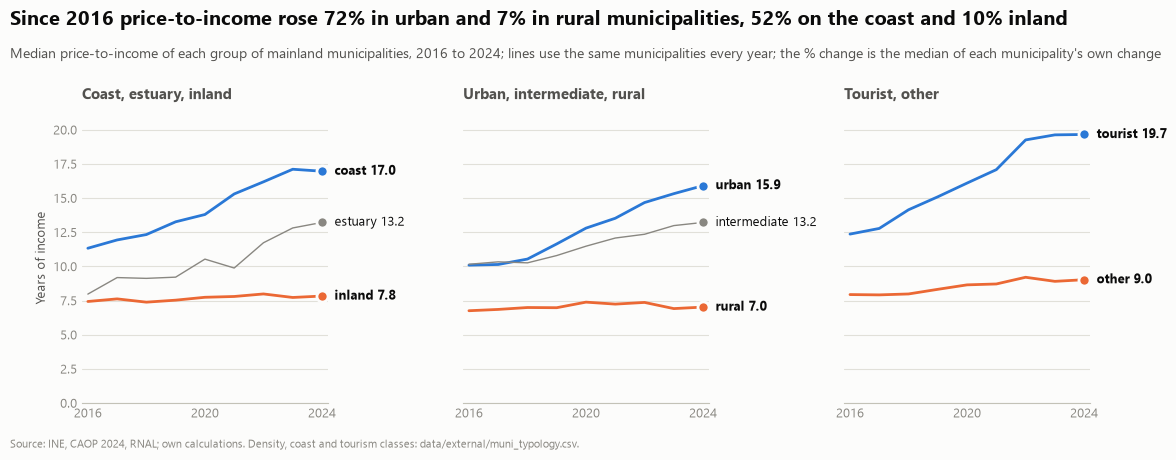

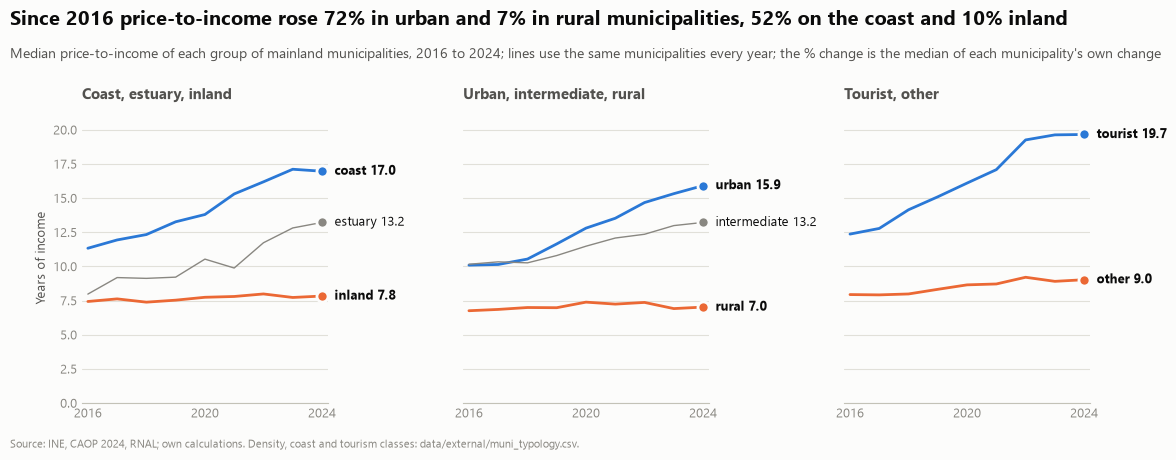

In [3]:
series = lambda dim, labels: {  # noqa: E731
    label: by_year[dim][label] for label in labels
}
change = {
    "coast": summary[summary["dimension"] == "coast_class"]
    .set_index("group")["pti_change_pct"]
    .to_dict(),
    "density": summary[summary["dimension"] == "density_class"]
    .set_index("group")["pti_change_pct"]
    .to_dict(),
    "tourist": summary[summary["dimension"] == "tourist"]
    .set_index("group")["pti_change_pct"]
    .to_dict(),
}
fig = charts.segment_trends(
    [
        {
            "title": "Coast, estuary, inland",
            "series": series("coast_class", ["coast", "inland", "estuary"]),
        },
        {
            "title": "Urban, intermediate, rural",
            "series": series("density_class", ["urban", "rural", "intermediate"]),
        },
        {"title": "Tourist, other", "series": series("tourist", ["tourist", "other"])},
    ],
    change,
    START,
    END,
)
style.save_fig(fig, "p2", "segment_pti_trends")
fig

## Step 2 — Adjusted differences: do the three dimensions overlap?
Coastal municipalities are denser and more touristic, so each comparison above partly repeats the others. A
regression of each municipality's log change in price-to-income (2016 to 2024) on all three dimensions at once
shows what is left of each; the second model compares only municipalities of the same district, the third
also controls the starting level (places that started high may have changed less). Robust (HC3) errors.

In [4]:
w = panel[panel["year"].isin([START, END])].pivot(
    index="muni_code", columns="year", values="pti_years"
)
cross = pd.DataFrame(
    {
        "dlog_pti": np.log(w[END] / w[START]),
        "log_pti_start": np.log(w[START]),
    }
).reset_index()
cross = cross.merge(mainland, on="muni_code").merge(
    panel[panel["year"] == END][["muni_code", "district"]], on="muni_code"
)
REFERENCE = {"coast_class": "inland", "density_class": "rural", "tourist": "other"}
MODELS = {
    "Groups only": {},
    "Same district": {"fixed_effects": "district"},
    "Same district, same starting level": {
        "fixed_effects": "district",
        "controls": ["log_pti_start"],
    },
}
adjusted = pd.concat(
    [
        desc.group_regression(cross, "dlog_pti", REFERENCE, **options).assign(model=name)
        for name, options in MODELS.items()
    ],
    ignore_index=True,
)
style.save_table(adjusted, "p2", "segment_adjusted_differences")
print(adjusted[["model", "term", "coef", "se", "p", "n_obs"]].round(3).to_string(index=False))

                             model                                   term   coef    se     p  n_obs
                       Groups only         coast_class: coast (vs inland)  0.210 0.037 0.000    271
                       Groups only       coast_class: estuary (vs inland)  0.261 0.057 0.000    271
                       Groups only density_class: intermediate (vs rural)  0.132 0.027 0.000    271
                       Groups only        density_class: urban (vs rural)  0.362 0.040 0.000    271
                       Groups only            tourist: tourist (vs other)  0.053 0.049 0.285    271
                     Same district         coast_class: coast (vs inland)  0.120 0.035 0.001    271
                     Same district       coast_class: estuary (vs inland)  0.077 0.054 0.154    271
                     Same district density_class: intermediate (vs rural)  0.118 0.028 0.000    271
                     Same district        density_class: urban (vs rural)  0.325 0.040 0.000    271


**Sensitivity to the class borders** (same district model): density borders (urban from, rural below) and the
tourist threshold changed.

In [5]:
rows = []
for urban_from, rural_below, tourist_from in (
    (500, 100, 25), (300, 50, 25), (1000, 200, 25), (500, 100, 15), (500, 100, 40),
):  # fmt: skip
    alt = cross.copy()
    dens = alt["density_per_km2_2021"]
    alt["density_class"] = np.where(
        dens >= urban_from, "urban", np.where(dens < rural_below, "rural", "intermediate")
    )
    alt["tourist"] = np.where(alt["al_per_1000_dwellings"] >= tourist_from, "tourist", "other")
    res = desc.group_regression(alt, "dlog_pti", REFERENCE, fixed_effects="district")
    rows.append(
        res.assign(urban_from=urban_from, rural_below=rural_below, tourist_from=tourist_from)
    )
sensitivity = pd.concat(rows, ignore_index=True)
style.save_table(sensitivity, "p2", "segment_threshold_sensitivity")
print(
    sensitivity.pivot_table(
        index=["urban_from", "rural_below", "tourist_from"],
        columns="term",
        values="coef",
        sort=False,
    )
    .round(2)
    .to_string()
)

term                                 coast_class: coast (vs inland)  coast_class: estuary (vs inland)  density_class: intermediate (vs rural)  density_class: urban (vs rural)  tourist: tourist (vs other)
urban_from rural_below tourist_from                                                                                                                                                                        
500        100         25                                      0.12                              0.08                                    0.12                             0.33                        -0.00
                       15                                      0.12                              0.08                                    0.12                             0.33                        -0.00
                       40                                      0.12                              0.08                                    0.12                             0.32          

## Step 3 — Do the drivers act differently by type? (foreign residents)
The foreign-resident coefficient of P2.02 (NUTS 3 × year effects) interacted with each dimension: the
first row is the effect in the reference group, the others the *difference* in the group named.

In [6]:
frame = pn.build_frame(panel)
frame = frame.join(
    ty.set_index("muni_code")[["coast_class", "density_class", "tourist"]], on="muni_code"
)
X = ["pop_change_ex_foreign_pct", "foreign_change_pct", "completions_per_1000", "pop_65plus_pct"]
rows = []
for dim, group, label in (
    ("coast_class", "coast", "coast"),
    ("density_class", "urban", "urban"),
    ("tourist", "tourist", "tourist"),
):
    flag = f"is_{label}"
    frame[flag] = (frame[dim] == group).astype(float)
    inter = f"foreign_x_{label}"
    frame[inter] = frame["foreign_change_pct"] * frame[flag]
    res = pn.fit(
        frame,
        pn.Spec(
            "log_pti", [*X, inter], effects="region_year", sample={"territory": ["continente"]}
        ),
    )
    t = pn.coef_table(res, f"foreign residents x {label}")
    rows.append(t[t["term"].isin(["foreign_change_pct", inter])])
hetero = pd.concat(rows, ignore_index=True)
style.save_table(hetero, "p2", "segment_foreign_interactions")
print(
    hetero[["spec", "term", "coef", "se", "p", "n_obs", "n_munis"]].round(4).to_string(index=False)
)

                       spec               term    coef     se      p  n_obs  n_munis
  foreign residents x coast foreign_change_pct  0.0276 0.0099 0.0051   2136      272
  foreign residents x coast    foreign_x_coast  0.0103 0.0101 0.3102   2136      272
  foreign residents x urban foreign_change_pct  0.0224 0.0088 0.0108   2136      272
  foreign residents x urban    foreign_x_urban  0.0396 0.0103 0.0001   2136      272
foreign residents x tourist foreign_change_pct  0.0379 0.0101 0.0002   2136      272
foreign residents x tourist  foreign_x_tourist -0.0199 0.0108 0.0642   2136      272


The three dimensions overlap, so the same model with all three interactions at once:

In [7]:
joint = pn.fit(
    frame,
    pn.Spec(
        "log_pti",
        [*X, "foreign_x_coast", "foreign_x_urban", "foreign_x_tourist"],
        effects="region_year",
        sample={"territory": ["continente"]},
    ),
)
joint_table = pn.coef_table(joint, "all three interactions")
joint_table = joint_table[joint_table["term"].str.contains("foreign")]
style.save_table(joint_table, "p2", "segment_foreign_interactions_joint")
print(joint_table[["term", "coef", "se", "p", "n_obs"]].round(4).to_string(index=False))

                     term    coef     se      p  n_obs
pop_change_ex_foreign_pct  0.0048 0.0028 0.0815   2136
       foreign_change_pct  0.0225 0.0102 0.0272   2136
          foreign_x_coast  0.0278 0.0085 0.0011   2136
          foreign_x_urban  0.0425 0.0092 0.0000   2136
        foreign_x_tourist -0.0325 0.0092 0.0004   2136


## Findings

1. **The deterioration is a coastal and urban phenomenon (RQ4.6).** Between 2016 and 2024 the median price-to-income
   rose 52% in the 57 coastal municipalities (11.3 to 17.0 years of income), 63% in the 9 estuary ones and 10% in the
   205 inland ones (7.0 to 7.4); 72% in the 32 urban municipalities (10.1 to 15.9), 34% in the 74 intermediate and 7%
   in the 165 rural ones (6.5 to 6.6); 47% in the 34 tourist municipalities (12.3 to 19.6) and 16% in the others.
2. **It is prices, and incomes grew least where prices grew most.** Real price per m² rose 84% on the coast and 41% inland,
   110% in urban and 33% in rural municipalities, while real median income rose less on the coast (25%) and in urban
   municipalities (24%) than inland (30%) and in rural ones (31%).
3. **Density matters most, then the coast; tourism adds nothing once those are accounted for.** Regressing each
   municipality's log change in price-to-income on all three dimensions, urban municipalities rose 0.36 log points
   (about 44%) more than rural ones and coastal ones 0.21 (about 23%) more than inland ones. Within the same
   district the gaps are 0.33 and 0.12 (38% and 13%). The tourist coefficient is 0.05 (p = 0.29) and 0.00 within the
   district; controlling the starting level as well it is 0.03 (p = 0.48). The tourist group is mostly coastal and
   dense (24 of 35 on the coast), so its raw gap is the coast's and the city's.
   Changing the class borders (urban from 300 to 1,000 residents per km², tourist from 15 to 40 rentals per 1,000
   dwellings) leaves the order unchanged: urban 0.22 to 0.35, coast 0.12 to 0.13, tourist −0.03 to 0.00 within
   the district.
4. **The foreign-resident association is strongest in dense coastal municipalities.** In the NUTS 3 × year model of
   P2.02 with all three interactions, the effect of one percentage point of population added through foreign
   residents is +2.3% in an inland, rural, non-tourist municipality, +2.8 points more on the coast, +4.3 points more in
   urban municipalities (both p ≤ 0.001) and 3.3 points *less* in tourist municipalities (p < 0.001). Each interaction
   alone gives a similar picture for urban (+4.0 points) and tourist (−2.0, p = 0.06) but not for the coast (+1.0,
   p = 0.31): the coast difference appears only once density and tourism are held fixed.

**Limits.** The three classes are proxies (shoreline in the CAOP boundaries, density in 2021, today's rental
registry), the tourist class covers only the mainland and is from the present, and the groups overlap and are small
(9 to 57 municipalities). The adjusted comparisons are associations: coastal and urban places also differ in
age, jobs and land. The interaction results use three overlapping interactions on 272 municipalities and are
exploratory; read the sign pattern, not single p-values. The 30 island municipalities are not in these comparisons.